# **Customer Churn EDA**

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load Your Dataset

In [2]:
df = pd.read_csv("Cleaned_Customer_Data 1.csv")

In [3]:
df.head()

,Customer_ID,Age,Gender,City,Tenure_Months,Contract_Type,Plan_Type,Monthly_Charges,Total_Charges,Payment_Method,Internet_Service,Support_Calls,Complaints,Satisfaction_Score,Discount_Percent,Referral,Churn,Risk_Score,Risk_Level
0,CP00001,34,Female,Mumbai,40,Monthly,Basic,₹543.00,"₹21,852.95",UPI,Yes,0,0,5,0%,Yes,No,2,Low
1,CP00002,32,Female,Mumbai,8,Annual,Standard,₹778.00,"₹5,704.82",UPI,Yes,2,0,5,10%,No,No,0,Low
2,CP00003,42,Male,Nagpur,54,Annual,Basic,₹536.00,"₹28,735.82",UPI,Yes,1,0,5,0%,No,No,0,Low
3,CP00004,18,Female,Mumbai,42,Annual,Basic,₹594.00,"₹25,224.35",Bank Transfer,Yes,0,0,4,0%,No,No,0,Low
4,CP00005,58,Male,Mumbai,19,Monthly,Basic,₹489.00,"₹9,159.93",Credit Card,No,1,0,4,0%,No,Yes,2,Low


### Check Dataset Size

In [4]:
df.shape

(10000, 19)

### Check Column Names

In [5]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'City', 'Tenure_Months',
       'Contract_Type', 'Plan_Type', 'Monthly_Charges', 'Total_Charges',
       'Payment_Method', 'Internet_Service', 'Support_Calls', 'Complaints',
       'Satisfaction_Score', 'Discount_Percent', 'Referral', 'Churn',
       'Risk_Score', 'Risk_Level'],
      dtype='object')

### Check Data Types

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Customer_ID         10000 non-null  object
 1   Age                 10000 non-null  int64 
 2   Gender              10000 non-null  object
 3   City                10000 non-null  object
 4   Tenure_Months       10000 non-null  int64 
 5   Contract_Type       10000 non-null  object
 6   Plan_Type           10000 non-null  object
 7   Monthly_Charges     10000 non-null  object
 8   Total_Charges       10000 non-null  object
 9   Payment_Method      10000 non-null  object
 10  Internet_Service    10000 non-null  object
 11  Support_Calls       10000 non-null  int64 
 12  Complaints          10000 non-null  int64 
 13  Satisfaction_Score  10000 non-null  int64 
 14  Discount_Percent    10000 non-null  object
 15  Referral            10000 non-null  object
 16  Churn               100

### Check Missing Values

In [136]:
df.isnull().sum()

Customer_ID                 0
Age                         0
Gender                      0
City                        0
Tenure_Months               0
Contract_Type               0
Plan_Type                   0
Monthly_Charges             0
Total_Charges               0
Payment_Method              0
Internet_Service            0
Support_Calls               0
Complaints                  0
Satisfaction_Score          0
Discount_Percent            0
Referral                    0
Churn                       0
Risk_Score                  0
Risk_Level                  0
Tenure_Group                0
Revenue_Segment             0
Revenue_Level               0
Customer_Priority           0
Churn_Probability           0
ML_Risk_Category            0
ML_Retention_Priority       0
ML_Prediction               0
ML_Predicted_Churn          0
Final_Retention_Priority    0
dtype: int64

In [137]:
df.isnull().sum().sum()

np.int64(0)

###  Check Duplicate Customers

In [138]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["Customer_ID"].duplicated().sum()

np.int64(0)

### Basic Statistical Summary

In [11]:
df.describe()

,Age,Tenure_Months,Support_Calls,Complaints,Satisfaction_Score,Risk_Score
count,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,35.670900,33.897300,1.23870,0.318400,4.530500,1.657800
std,10.451675,15.900668,1.65021,0.738157,0.775455,1.514902
min,18.000000,1.000000,0.00000,0.000000,1.000000,0.000000
25%,28.000000,21.000000,0.00000,0.000000,4.000000,0.000000
50%,36.000000,32.000000,1.00000,0.000000,5.000000,2.000000
75%,43.000000,45.000000,2.00000,0.000000,5.000000,2.000000
max,75.000000,72.000000,10.00000,5.000000,5.000000,10.000000


### Check Churn Distribution

In [12]:
df["Churn"].value_counts()

Churn
No     7808
Yes    2192
Name: count, dtype: int64

In [139]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     78.08
Yes    21.92
Name: proportion, dtype: float64

### First Python Visualization

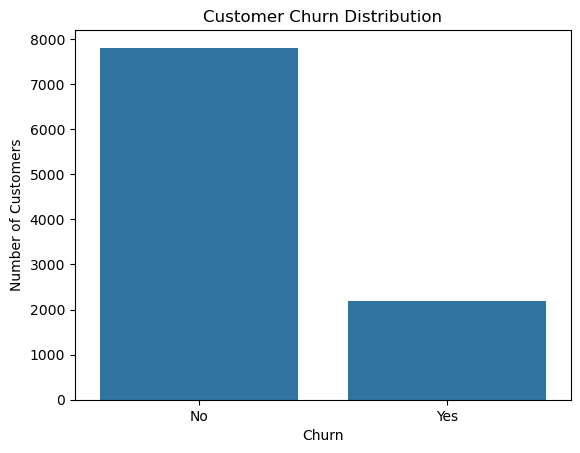

In [14]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

### Churn Rate by Contract Type

In [15]:
contract_churn = pd.crosstab(
    df["Contract_Type"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract_Type,,
2-Year,94.059406,5.940594
2-year,83.333333,16.666667
Annual,86.695279,13.304721
Monthly,68.016117,31.983883
annual,100.000000,0.000000


In [16]:
contract_churn["Yes"].sort_values(ascending=False)

Contract_Type
Monthly    31.983883
2-year     16.666667
Annual     13.304721
2-Year      5.940594
annual      0.000000
Name: Yes, dtype: float64

### Visualize Contract Churn

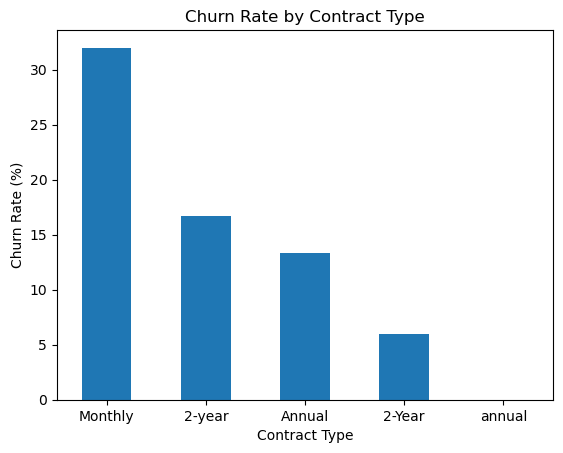

In [17]:
contract_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Churn by Tenure

In [18]:
df["Tenure_Group"] = pd.cut(
    df["Tenure_Months"],
    bins=[0, 6, 12, 24, 36, float("inf")],
    labels=["0-6 Months", "7-12 Months", "13-24 Months", "25-36 Months", "37+ Months"]
)

In [19]:
tenure_churn = pd.crosstab(
    df["Tenure_Group"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn

Churn,No,Yes
Tenure_Group,,
0-6 Months,44.242424,55.757576
7-12 Months,69.016698,30.983302
13-24 Months,72.178683,27.821317
25-36 Months,77.315690,22.684310
37+ Months,84.801171,15.198829


In [20]:
tenure_churn["Yes"]

Tenure_Group
0-6 Months      55.757576
7-12 Months     30.983302
13-24 Months    27.821317
25-36 Months    22.684310
37+ Months      15.198829
Name: Yes, dtype: float64

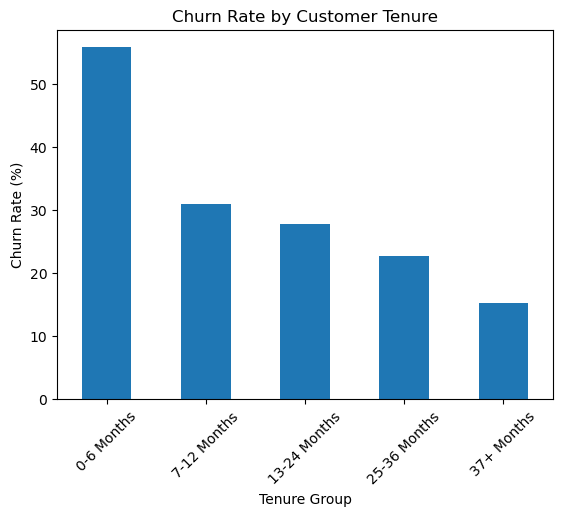

In [21]:
tenure_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.show()

###  Churn by Plan Type

In [22]:
plan_churn = pd.crosstab(
    df["Plan_Type"],
    df["Churn"],
    normalize="index"
) * 100

plan_churn["Yes"].sort_values(ascending=False)

Plan_Type
Premium     23.092170
Standard    22.050428
Basic       21.148756
Name: Yes, dtype: float64

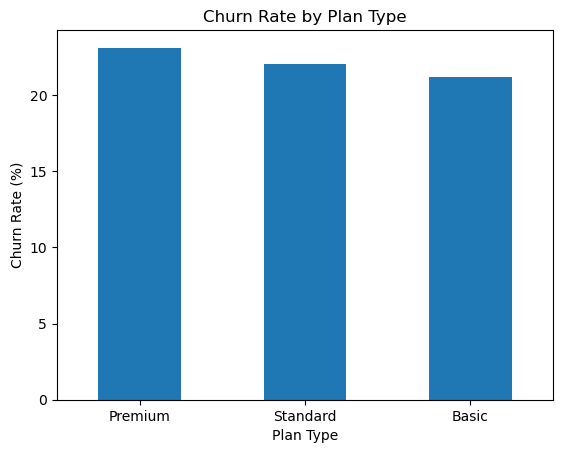

In [23]:
plan_churn["Yes"].sort_values(ascending=False).plot(kind="bar")

plt.title("Churn Rate by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Churn by Satisfaction Score

In [24]:
satisfaction_churn = pd.crosstab(
    df["Satisfaction_Score"],
    df["Churn"],
    normalize="index"
) * 100

satisfaction_churn["Yes"]

Satisfaction_Score
1    73.255814
2    75.242718
3    43.540670
4    19.564340
5    18.418661
Name: Yes, dtype: float64

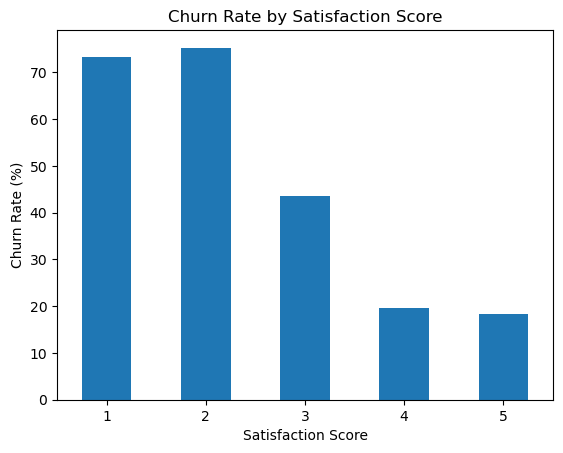

In [25]:
satisfaction_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Satisfaction Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Churn by Support Calls

In [26]:
support_churn = pd.crosstab(
    df["Support_Calls"],
    df["Churn"],
    normalize="index"
) * 100

support_churn["Yes"]

Support_Calls
0     18.368267
1     17.776006
2     22.799423
3     22.876712
4     36.020151
5     48.594378
6     50.375940
7     71.641791
8     66.666667
9     84.615385
10    77.777778
Name: Yes, dtype: float64

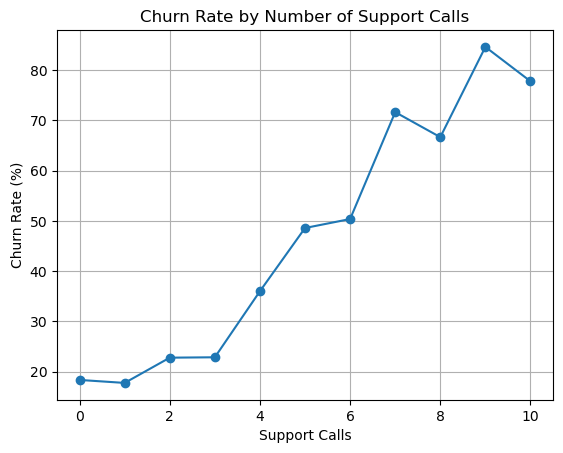

In [27]:
support_churn["Yes"].plot(kind="line", marker="o")

plt.title("Churn Rate by Number of Support Calls")
plt.xlabel("Support Calls")
plt.ylabel("Churn Rate (%)")
plt.grid()
plt.show()

### Churn by Complaints

In [28]:
complaint_churn = pd.crosstab(
    df["Complaints"],
    df["Churn"],
    normalize="index"
) * 100

complaint_churn["Yes"]

Complaints
0    18.182951
1    22.841727
2    49.078727
3    69.500000
4    70.175439
5    70.000000
Name: Yes, dtype: float64

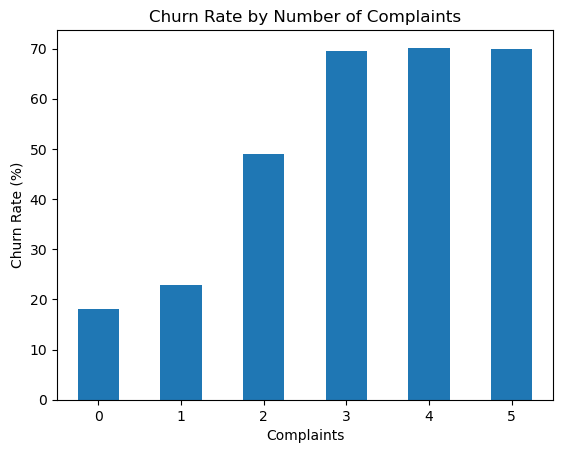

In [29]:
complaint_churn["Yes"].plot(kind="bar")

plt.title("Churn Rate by Number of Complaints")
plt.xlabel("Complaints")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Monthly Charges vs Churn

In [140]:
df["Monthly_Charges"] = (
    df["Monthly_Charges"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["Monthly_Charges"] = pd.to_numeric(
    df["Monthly_Charges"],
    errors="coerce"
)

In [143]:
df["Monthly_Charges"].dtype

dtype('float64')

In [144]:
df.groupby("Churn")["Monthly_Charges"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
No,7808,696.261270,694.0,389.0,1147.0
Yes,2192,706.215328,704.0,389.0,1144.0


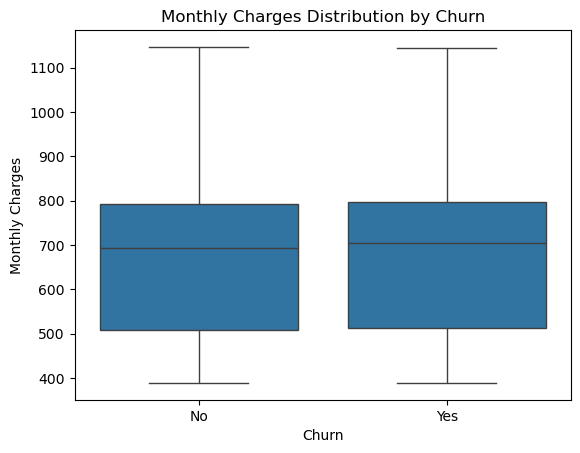

In [36]:
sns.boxplot(
    data=df,
    x="Churn",
    y="Monthly_Charges"
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

 ### Total Charges vs Churn

In [38]:
df["Total_Charges"] = (
    df["Total_Charges"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["Total_Charges"] = pd.to_numeric(
    df["Total_Charges"],
    errors="coerce"
)

In [39]:
df["Total_Charges"].dtype

dtype('float64')

In [40]:
df.groupby("Churn")["Total_Charges"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Churn,,,,,
No,7808,23864.773450,21229.725,1056.47,80703.28
Yes,2192,20369.352486,17652.445,626.86,72589.21


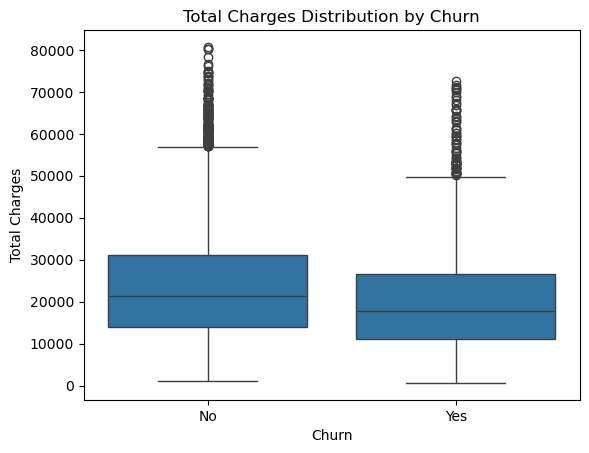

In [41]:
sns.boxplot(
    data=df,
    x="Churn",
    y="Total_Charges"
)

plt.title("Total Charges Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Total Charges")
plt.show()

### Correlation Analysis

In [42]:
numeric_columns = [
    "Age",
    "Tenure_Months",
    "Monthly_Charges",
    "Total_Charges",
    "Support_Calls",
    "Complaints",
    "Satisfaction_Score",
    "Risk_Score"
]

In [43]:
correlation_matrix = df[numeric_columns].corr()

correlation_matrix

,Age,Tenure_Months,Monthly_Charges,Total_Charges,Support_Calls,Complaints,Satisfaction_Score,Risk_Score
Age,1.000000,-0.003795,-0.002050,-0.006662,0.001308,-0.000430,-0.001161,-0.002970
Tenure_Months,-0.003795,1.000000,-0.006922,0.813394,0.004304,0.004618,0.000704,-0.218930
Monthly_Charges,-0.002050,-0.006922,1.000000,0.512966,-0.063214,-0.050623,0.046082,0.200512
Total_Charges,-0.006662,0.813394,0.512966,1.000000,-0.028550,-0.022405,0.024978,-0.053749
Support_Calls,0.001308,0.004304,-0.063214,-0.028550,1.000000,0.804354,-0.654871,0.513224
Complaints,-0.000430,0.004618,-0.050623,-0.022405,0.804354,1.000000,-0.741698,0.542745
Satisfaction_Score,-0.001161,0.000704,0.046082,0.024978,-0.654871,-0.741698,1.000000,-0.480038
Risk_Score,-0.002970,-0.218930,0.200512,-0.053749,0.513224,0.542745,-0.480038,1.000000


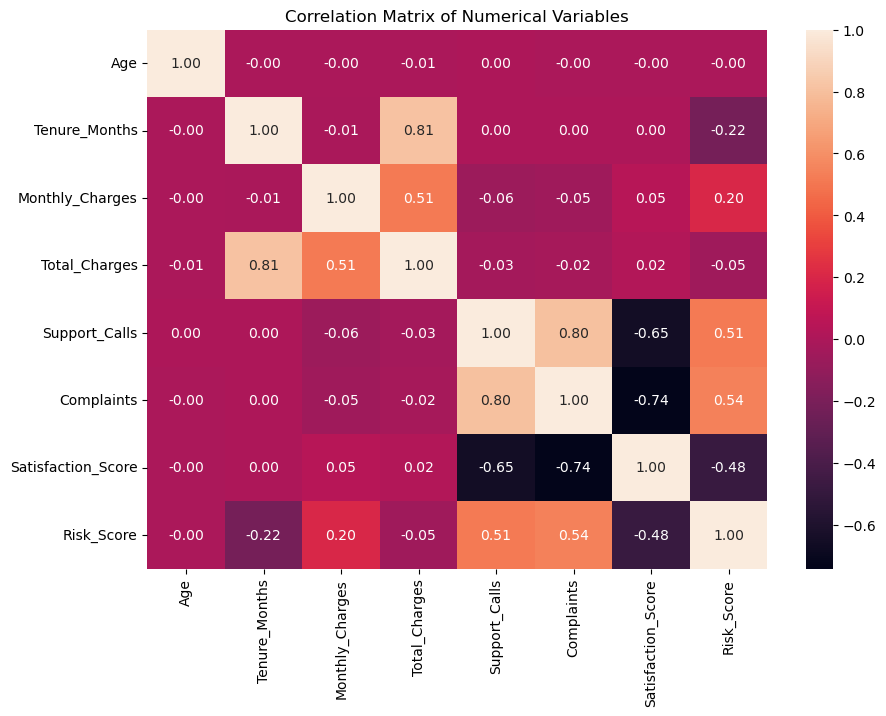

In [44]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

## Python EDA — Key Findings

1. Overall customer churn is 21.92%.

2. Monthly-contract customers have the highest observed churn
   among contract types at approximately 31.98%.

3. Customers with 0–6 months of tenure have the highest
   observed churn rate at approximately 56%.

4. Premium customers show the highest observed churn rate
   among the three plan types at approximately 23.09%.

5. Lower satisfaction and higher support interactions are
   associated with higher observed churn.

6. Complaint frequency can be analyzed as an additional
   customer experience indicator.

7. Monthly and total charges help evaluate the financial
   characteristics of churned customers.

8. Correlation analysis provides relationships between
   numerical variables but does not establish causation.

# **Customer Segmentation**

### Check your current data

In [45]:
df.head()

,Customer_ID,Age,Gender,City,Tenure_Months,Contract_Type,Plan_Type,Monthly_Charges,Total_Charges,Payment_Method,Internet_Service,Support_Calls,Complaints,Satisfaction_Score,Discount_Percent,Referral,Churn,Risk_Score,Risk_Level,Tenure_Group
0,CP00001,34,Female,Mumbai,40,Monthly,Basic,543.0,21852.95,UPI,Yes,0,0,5,0%,Yes,No,2,Low,37+ Months
1,CP00002,32,Female,Mumbai,8,Annual,Standard,778.0,5704.82,UPI,Yes,2,0,5,10%,No,No,0,Low,7-12 Months
2,CP00003,42,Male,Nagpur,54,Annual,Basic,536.0,28735.82,UPI,Yes,1,0,5,0%,No,No,0,Low,37+ Months
3,CP00004,18,Female,Mumbai,42,Annual,Basic,594.0,25224.35,Bank Transfer,Yes,0,0,4,0%,No,No,0,Low,37+ Months
4,CP00005,58,Male,Mumbai,19,Monthly,Basic,489.0,9159.93,Credit Card,No,1,0,4,0%,No,Yes,2,Low,13-24 Months


In [46]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'City', 'Tenure_Months',
       'Contract_Type', 'Plan_Type', 'Monthly_Charges', 'Total_Charges',
       'Payment_Method', 'Internet_Service', 'Support_Calls', 'Complaints',
       'Satisfaction_Score', 'Discount_Percent', 'Referral', 'Churn',
       'Risk_Score', 'Risk_Level', 'Tenure_Group'],
      dtype='object')

### Create Tenure Segments

In [47]:
df["Tenure_Group"].value_counts()

Tenure_Group
37+ Months      4099
25-36 Months    2645
13-24 Months    2552
7-12 Months      539
0-6 Months       165
Name: count, dtype: int64

In [48]:
tenure_segment = df.groupby("Tenure_Group", observed=False).agg(
    Customers=("Customer_ID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
)

tenure_segment["Churn_Rate"] = (
    tenure_segment["Churned_Customers"]
    / tenure_segment["Customers"]
    * 100
)

tenure_segment

,Customers,Churned_Customers,Churn_Rate
Tenure_Group,,,
0-6 Months,165,92,55.757576
7-12 Months,539,167,30.983302
13-24 Months,2552,710,27.821317
25-36 Months,2645,600,22.684310
37+ Months,4099,623,15.198829


### Create Revenue Segments

In [49]:
df["Revenue_Segment"] = pd.qcut(
    df["Monthly_Charges"],
    q=4,
    labels=["Low Revenue", "Medium Revenue", "High Revenue", "Very High Revenue"]
)

In [50]:
df["Revenue_Segment"].value_counts()

Revenue_Segment
Low Revenue          2501
High Revenue         2500
Very High Revenue    2500
Medium Revenue       2499
Name: count, dtype: int64

### Analyze Churn by Revenue Segment

In [51]:
revenue_segment = df.groupby(
    "Revenue_Segment",
    observed=False
).agg(
    Customers=("Customer_ID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum()),
    Avg_Monthly_Charges=("Monthly_Charges", "mean")
)

revenue_segment["Churn_Rate"] = (
    revenue_segment["Churned_Customers"]
    / revenue_segment["Customers"]
    * 100
)

revenue_segment

,Customers,Churned_Customers,Avg_Monthly_Charges,Churn_Rate
Revenue_Segment,,,,
Low Revenue,2501,528,455.529388,21.111555
Medium Revenue,2499,523,603.633453,20.928371
High Revenue,2500,566,745.866400,22.640000
Very High Revenue,2500,575,988.802800,23.000000


### Visualize Revenue Segments

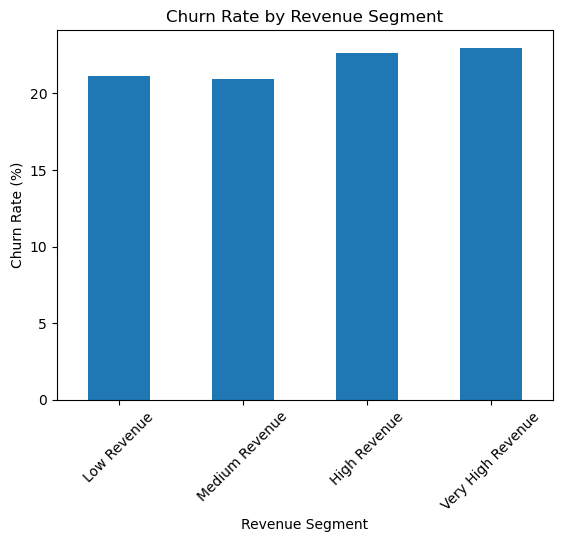

In [52]:
revenue_segment["Churn_Rate"].plot(kind="bar")

plt.title("Churn Rate by Revenue Segment")
plt.xlabel("Revenue Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)

plt.show()

### Analyze Risk Segments

In [53]:
risk_segment = df.groupby("Risk_Level").agg(
    Customers=("Customer_ID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum()),
    Avg_Monthly_Charges=("Monthly_Charges", "mean")
)

risk_segment["Churn_Rate"] = (
    risk_segment["Churned_Customers"]
    / risk_segment["Customers"]
    * 100
)

risk_segment

,Customers,Churned_Customers,Avg_Monthly_Charges,Churn_Rate
Risk_Level,,,,
High,158,139,674.759494,87.974684
Low,9187,1694,697.572875,18.439099
Medium,655,359,716.363359,54.809160


### Visualize Risk Segments

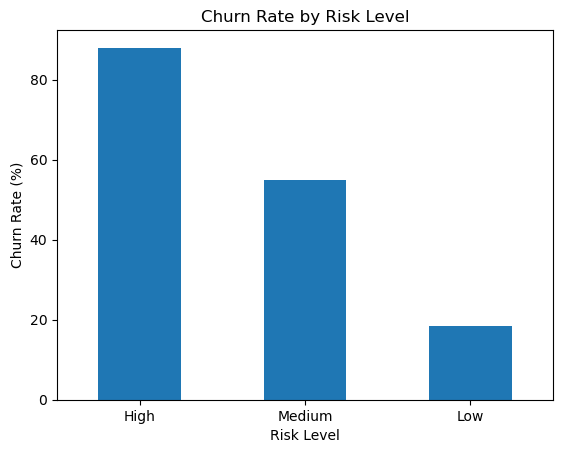

In [54]:
risk_segment["Churn_Rate"].sort_values(ascending=False).plot(kind="bar")

plt.title("Churn Rate by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()


### Create High/Low Revenue Flag

In [55]:
revenue_threshold = df["Monthly_Charges"].quantile(0.75)

revenue_threshold

np.float64(793.25)

In [56]:
df["Revenue_Level"] = np.where(
    df["Monthly_Charges"] >= revenue_threshold,
    "High Revenue",
    "Standard Revenue"
)

In [57]:
df["Revenue_Level"].value_counts()

Revenue_Level
Standard Revenue    7500
High Revenue        2500
Name: count, dtype: int64

### Create Priority Segment

In [58]:
df["Customer_Priority"] = np.select(
    [
        (df["Risk_Level"] == "High") &
        (df["Revenue_Level"] == "High Revenue"),

        (df["Risk_Level"] == "High") &
        (df["Revenue_Level"] == "Standard Revenue"),

        (df["Risk_Level"] == "Medium"),

        (df["Risk_Level"] == "Low")
    ],
    [
        "Critical Priority",
        "High Risk",
        "Medium Priority",
        "Low Priority"
    ],
    default="Low Priority"
)

In [59]:
df["Customer_Priority"].value_counts()

Customer_Priority
Low Priority         9187
Medium Priority       655
High Risk             128
Critical Priority      30
Name: count, dtype: int64

### Analyze Customer Priority

In [60]:
priority_analysis = df.groupby("Customer_Priority").agg(
    Customers=("Customer_ID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum()),
    Monthly_Revenue=("Monthly_Charges", "sum")
)

priority_analysis["Churn_Rate"] = (
    priority_analysis["Churned_Customers"]
    / priority_analysis["Customers"]
    * 100
)

priority_analysis

,Customers,Churned_Customers,Monthly_Revenue,Churn_Rate
Customer_Priority,,,,
Critical Priority,30,27,28535.0,90.000000
High Risk,128,112,78077.0,87.500000
Low Priority,9187,1694,6408602.0,18.439099
Medium Priority,655,359,469218.0,54.809160


### Find Critical Priority Customers

In [61]:
critical_customers = df[
    df["Customer_Priority"] == "Critical Priority"
]

critical_customers[
    [
        "Customer_ID",
        "Contract_Type",
        "Plan_Type",
        "Tenure_Months",
        "Monthly_Charges",
        "Support_Calls",
        "Complaints",
        "Satisfaction_Score",
        "Risk_Score",
        "Risk_Level",
        "Churn"
    ]
].head(20)

,Customer_ID,Contract_Type,Plan_Type,Tenure_Months,Monthly_Charges,Support_Calls,Complaints,Satisfaction_Score,Risk_Score,Risk_Level,Churn
335,CP00336,Monthly,Premium,43,1053.0,6,3,1,8,High,No
769,CP00770,Monthly,Premium,27,1090.0,8,4,1,8,High,Yes
1491,CP01492,Monthly,Standard,14,809.0,8,4,2,8,High,Yes
1718,CP01719,Monthly,Premium,22,948.0,6,2,2,8,High,Yes
2411,CP02412,Monthly,Premium,3,1050.0,4,2,4,8,High,Yes
2444,CP02445,Monthly,Premium,20,998.0,4,2,2,8,High,Yes
2669,CP02670,Monthly,Premium,27,976.0,4,2,2,8,High,Yes
2730,CP02731,Monthly,Premium,52,1035.0,7,2,2,8,High,Yes
2765,CP02766,Monthly,Premium,64,949.0,9,3,2,8,High,Yes
2842,CP02843,Monthly,Premium,29,966.0,5,3,1,8,High,Yes


### Find Active Critical Customers

In [62]:
active_critical_customers = df[
    (df["Customer_Priority"] == "Critical Priority") &
    (df["Churn"] == "No")
]


In [63]:
active_critical_customers[
    [
        "Customer_ID",
        "Contract_Type",
        "Plan_Type",
        "Tenure_Months",
        "Monthly_Charges",
        "Support_Calls",
        "Complaints",
        "Satisfaction_Score",
        "Risk_Score",
        "Risk_Level"
    ]
].sort_values(
    by=["Risk_Score", "Monthly_Charges"],
    ascending=[False, False]
).head(20)

,Customer_ID,Contract_Type,Plan_Type,Tenure_Months,Monthly_Charges,Support_Calls,Complaints,Satisfaction_Score,Risk_Score,Risk_Level
335,CP00336,Monthly,Premium,43,1053.0,6,3,1,8,High
9802,CP09803,Monthly,Premium,5,1046.0,3,2,2,8,High
3229,CP03230,Monthly,Standard,14,816.0,6,4,1,8,High


### Create a Customer Segment Summary

In [64]:
segment_summary = df.groupby(
    ["Risk_Level", "Revenue_Level"]
).agg(
    Customers=("Customer_ID", "count"),
    Churned_Customers=("Churn", lambda x: (x == "Yes").sum()),
    Monthly_Revenue=("Monthly_Charges", "sum")
).reset_index()

segment_summary["Churn_Rate"] = (
    segment_summary["Churned_Customers"]
    / segment_summary["Customers"]
    * 100
)

segment_summary

,Risk_Level,Revenue_Level,Customers,Churned_Customers,Monthly_Revenue,Churn_Rate
0,High,High Revenue,30,27,28535.0,90.000000
1,High,Standard Revenue,128,112,78077.0,87.500000
2,Low,High Revenue,2288,445,2266126.0,19.449301
3,Low,Standard Revenue,6899,1249,4142476.0,18.104073
4,Medium,High Revenue,182,103,177346.0,56.593407
5,Medium,Standard Revenue,473,256,291872.0,54.122622


### Create a Business Segmentation Chart

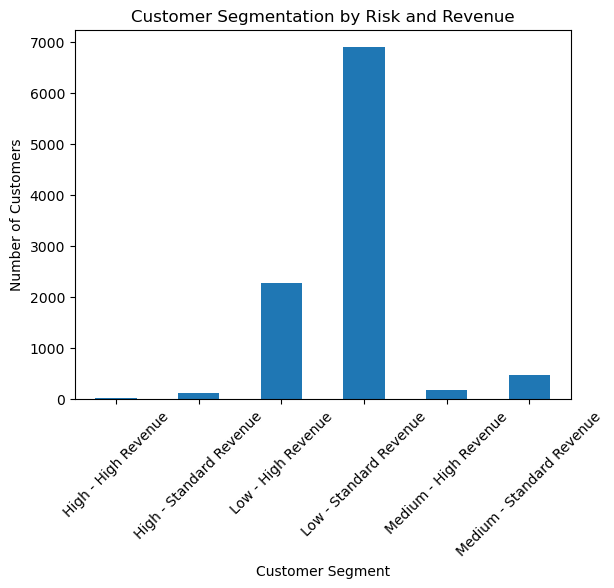

In [65]:
segment_summary["Segment"] = (
    segment_summary["Risk_Level"]
    + " - "
    + segment_summary["Revenue_Level"]
)

segment_summary.set_index("Segment")["Customers"].plot(kind="bar")

plt.title("Customer Segmentation by Risk and Revenue")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

# Customer Segmentation

Customer segmentation was performed to identify groups with
different retention and revenue priorities.

The analysis used three dimensions:

1. Customer Tenure
2. Monthly Revenue/Charges
3. Rule-Based Churn Risk

Customers were further classified into priority groups by
combining risk level with revenue level.

### Key Business Objective

The objective was to identify active customers who have both:

- High observed churn risk
- High monthly revenue contribution

These customers represent the highest retention priority.

### Business Application

- Low-risk customers → standard engagement
- Medium-risk customers → proactive monitoring
- High-risk customers → targeted retention
- High-risk + high-revenue customers → critical retention priority

The segmentation is designed for prioritization and does not
imply that the identified characteristics cause churn.

# Conclusion

The analysis identified key customer segments and churn patterns
using Python exploratory analysis and customer segmentation.

The findings were then incorporated into the Power BI dashboard
to support business decision-making and retention strategy.

The analysis focuses on identifying associations and
prioritization opportunities and does not establish causal
relationships.

# Business Recommendations

## Key Findings

- Overall observed churn rate is 21.92%.
- Monthly-contract customers show the highest observed churn among contract types at approximately 31.98%.
- Customers with 0–6 months of tenure show the highest observed churn at approximately 56%.
- High-risk customers represent a small segment but have an observed churn rate of approximately 88%.
- Lower satisfaction and higher support interactions can be used as customer-experience indicators.
- High-risk active customers can be prioritized for retention activities.

## Recommendations

1. Launch a First 180-Day Retention Program.
2. Encourage eligible monthly-contract customers to move to longer-term plans.
3. Create a dedicated high-risk retention queue.
4. Prioritize high-risk and high-value active customers.
5. Introduce a customer satisfaction recovery process.
6. Proactively follow up with customers showing repeated support interactions.
7. Monitor complaints and customer-experience indicators.

## Business Limitation

These findings represent observed associations within the dataset.
They should be used to support business prioritization and further
investigation rather than interpreted as proof of causal relationships.